# 6. Model Training — LightGBM
Baseline đầu tiên trong chuỗi so sánh model. Train + đánh giá qua group k-fold (5 fold, ranh giới đã chốt ở bước preprocessing), lưu model từng fold vào `model/checkpoints/lightgbm/`, và ghi kết quả vào bảng so sánh chung `model/results/cv_results.csv` để đối chiếu với các model train sau (XGBoost, Random Forest, Logistic Regression).

## 6.0 Import & cấu hình

In [ ]:
import pandas as pd
import numpy as np
import json
import os
import time
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
import gc

CHECKPOINT_DIR = "../data/checkpoints"
MODEL_DIR = "checkpoints/lightgbm"  
RESULTS_PATH = "results/cv_results.csv"
MODEL_NAME = "lightgbm"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(os.path.dirname(RESULTS_PATH), exist_ok=True)

RISK_ORDER = {"Normal": 0, "Watch": 1, "Alert": 2, "Critical": 3}
CLASS_NAMES = ["Normal", "Watch", "Alert", "Critical"]
RANDOM_STATE = 42

## 6.1 Load checkpoint từ bước preprocessing

In [16]:
dev_df = pd.read_parquet(f"{CHECKPOINT_DIR}/dev_df.parquet")
test_df = pd.read_parquet(f"{CHECKPOINT_DIR}/test_df.parquet")
manifest = json.load(open(f"{CHECKPOINT_DIR}/split_manifest.json"))

FEATURE_COLS = manifest["feature_cols"]
TARGET_COL = manifest["target_col"]
N_FOLDS = manifest["n_folds"]

print(f"dev_df: {dev_df.shape}, test_df: {test_df.shape}, n_folds={N_FOLDS}")

dev_df: (308881, 48), test_df: (60550, 47), n_folds=192


## 6.2 Encode feature & chuẩn bị X/y

In [17]:
def encode_features(d):
    d = d.copy()
    d["risk_level"] = d["risk_level"].map(RISK_ORDER).astype(int)
    return d

dev_enc = encode_features(dev_df)
X_dev = dev_enc[FEATURE_COLS].astype(np.float32)   
y_dev = dev_enc[TARGET_COL].map(RISK_ORDER).astype(int)
fold_id = dev_enc["fold_id"].astype(int)

## 6.3 Hàm ghi kết quả vào bảng so sánh chung
Append từng dòng `(model_name, fold_id, metric...)` vào `results/cv_results.csv` — dùng chung cho mọi notebook model sau này, để không phải tự gom tay nhiều file kết quả.

In [18]:
def already_done(results_path, model_name, fold_id):
    if not os.path.exists(results_path):
        return False
    df = pd.read_csv(results_path)
    return ((df["model_name"] == model_name) & (df["fold_id"] == fold_id)).any()

def log_fold_result(results_path, model_name, fold_id, n_val, train_seconds, y_true, y_pred):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1, 2, 3], zero_division=0
    )
    row = {
        "model_name": model_name, "fold_id": fold_id, "n_val": n_val,
        "train_seconds": round(train_seconds, 2),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }
    for i, cls in enumerate(CLASS_NAMES):
        row[f"precision_{cls}"] = precision[i]
        row[f"recall_{cls}"] = recall[i]
        row[f"f1_{cls}"] = f1[i]
        row[f"support_{cls}"] = support[i]

    df_row = pd.DataFrame([row])
    header = not os.path.exists(results_path)
    df_row.to_csv(results_path, mode="a", header=header, index=False)
    return row

## 6.4 Vòng lặp group k-fold: train + lưu model + ghi kết quả

In [19]:
MAX_WEIGHT_RATIO = 100  

def macro_recall_feval(y_true, y_pred_raw):
    """Custom eval: theo dõi macro-recall thay vì chỉ multi_logloss, để early stopping
    không bỏ qua khả năng phát hiện Alert/Critical."""
    y_pred_labels = np.argmax(y_pred_raw, axis=1)
    _, recall, _, _ = precision_recall_fscore_support(
        y_true, y_pred_labels, labels=[0, 1, 2, 3], zero_division=0
    )
    return "macro_recall", recall.mean(), True  

LGB_PARAMS = dict(
    objective="multiclass", num_class=4,
    n_estimators=500, learning_rate=0.05, num_leaves=31,
    boosting_type="goss",              
    feature_fraction=0.8,             
    random_state=RANDOM_STATE, verbosity=-1,
    n_jobs=-1,                     
)

oof_pred = np.full(len(dev_enc), -1)
oof_proba = np.full((len(dev_enc), 4), np.nan) 

for k in range(N_FOLDS):
    tr_mask = fold_id != k
    va_mask = fold_id == k
    fold_model_path = f"{MODEL_DIR}/fold_{k}.txt"

    if os.path.exists(fold_model_path) and already_done(RESULTS_PATH, MODEL_NAME, k):
        booster = lgb.Booster(model_file=fold_model_path)
        proba = booster.predict(X_dev[va_mask])
        oof_pred[va_mask.values] = np.argmax(proba, axis=1)
        oof_proba[va_mask.values] = proba
        print(f"[SKIP] Fold {k} đã có model + kết quả, khôi phục oof từ checkpoint")
        continue

    X_tr, y_tr = X_dev[tr_mask], y_dev[tr_mask]
    X_va, y_va = X_dev[va_mask], y_dev[va_mask]

    classes = np.unique(y_tr)
    weights = compute_class_weight("balanced", classes=classes, y=y_tr)
    weights = np.clip(weights, None, weights.min() * MAX_WEIGHT_RATIO)  
    sample_weight = y_tr.map(dict(zip(classes, weights)))

    t0 = time.time()
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(
        X_tr, y_tr, sample_weight=sample_weight,
        eval_set=[(X_va, y_va)],
        eval_metric=macro_recall_feval,        
        callbacks=[lgb.early_stopping(30, verbose=False)],
    )
    train_seconds = time.time() - t0

    proba = model.predict_proba(X_va)
    pred = np.argmax(proba, axis=1)
    oof_pred[va_mask.values] = pred
    oof_proba[va_mask.values] = proba

    model.booster_.save_model(f"{MODEL_DIR}/fold_{k}.txt")
    result_row = log_fold_result(RESULTS_PATH, MODEL_NAME, k, va_mask.sum(), train_seconds, y_va, pred)

    print(f"Fold {k}: macro_f1={result_row['macro_f1']:.3f}, "
          f"recall_Critical={result_row['recall_Critical']:.3f}, "
          f"({train_seconds:.1f}s) — đã lưu model + ghi kết quả")
    del model, X_tr, X_va, y_tr, y_va, proba
    gc.collect()

np.save(f"{MODEL_DIR}/oof_proba.npy", oof_proba)   

d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 0: macro_f1=0.371, recall_Critical=0.500, (10.1s) — đã lưu model + ghi kết quả


d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: macro_f1=0.337, recall_Critical=0.250, (7.2s) — đã lưu model + ghi kết quả


d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


...

Fold 189: macro_f1=0.381, recall_Critical=0.349, (3.1s) — đã lưu model + ghi kết quả


d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 190: macro_f1=0.559, recall_Critical=0.000, (7.3s) — đã lưu model + ghi kết quả


d:\VEDC2026\SPO2-RESEARCH\respiratory-risk-classifier\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 191: macro_f1=0.498, recall_Critical=0.000, (4.3s) — đã lưu model + ghi kết quả


## 6.5 Xem lại kết quả LightGBM vừa ghi (đọc lại từ file chung)

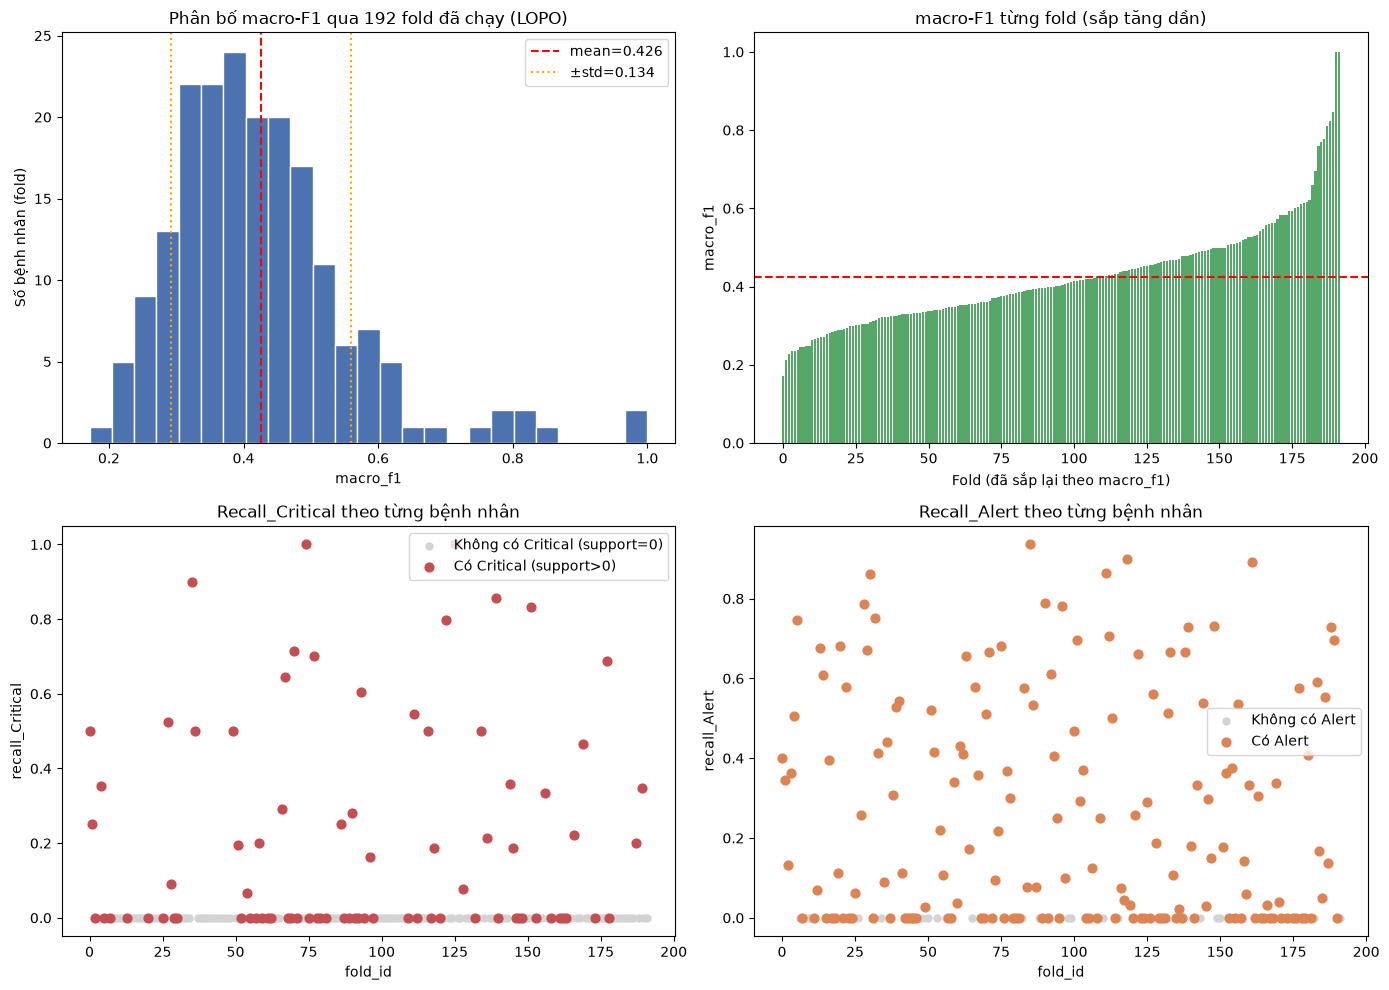

Macro-F1: 0.426 ± 0.134  (192/192 fold đã chạy)
Bệnh nhân có Critical: 81, model bắt được ít nhất 1 ca: 38 (46.9%)


In [20]:
import matplotlib.pyplot as plt

all_results = pd.read_csv(RESULTS_PATH)
lgbm_results = all_results[all_results["model_name"] == MODEL_NAME].sort_values("fold_id")

mean_f1, std_f1 = lgbm_results["macro_f1"].mean(), lgbm_results["macro_f1"].std()
has_critical = lgbm_results["support_Critical"] > 0
has_alert = lgbm_results["support_Alert"] > 0

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Phân bố macro-F1 qua các fold
axes[0, 0].hist(lgbm_results["macro_f1"], bins=25, color="#4c72b0", edgecolor="white")
axes[0, 0].axvline(mean_f1, color="red", linestyle="--", label=f"mean={mean_f1:.3f}")
axes[0, 0].axvline(mean_f1 - std_f1, color="orange", linestyle=":", label=f"±std={std_f1:.3f}")
axes[0, 0].axvline(mean_f1 + std_f1, color="orange", linestyle=":")
axes[0, 0].set_title(f"Phân bố macro-F1 qua {len(lgbm_results)} fold đã chạy (LOPO)")
axes[0, 0].set_xlabel("macro_f1"); axes[0, 0].set_ylabel("Số bệnh nhân (fold)")
axes[0, 0].legend()

# 2. macro-F1 từng fold, sắp tăng dần -> lộ rõ nhóm fold tệ nhất
sorted_f1 = lgbm_results.sort_values("macro_f1")
axes[0, 1].bar(range(len(sorted_f1)), sorted_f1["macro_f1"], color="#55a868")
axes[0, 1].axhline(mean_f1, color="red", linestyle="--")
axes[0, 1].set_title("macro-F1 từng fold (sắp tăng dần)")
axes[0, 1].set_xlabel("Fold (đã sắp lại theo macro_f1)"); axes[0, 1].set_ylabel("macro_f1")

# 3. recall_Critical: phân biệt "không có Critical" (support=0) và "có nhưng bị bỏ sót"
axes[1, 0].scatter(lgbm_results.loc[~has_critical, "fold_id"], lgbm_results.loc[~has_critical, "recall_Critical"],
                    color="lightgray", label="Không có Critical (support=0)", s=25)
axes[1, 0].scatter(lgbm_results.loc[has_critical, "fold_id"], lgbm_results.loc[has_critical, "recall_Critical"],
                    color="#c44e52", label="Có Critical (support>0)", s=40)
axes[1, 0].set_title("Recall_Critical theo từng bệnh nhân")
axes[1, 0].set_xlabel("fold_id"); axes[1, 0].set_ylabel("recall_Critical")
axes[1, 0].legend()

# 4. recall_Alert tương tự
axes[1, 1].scatter(lgbm_results.loc[~has_alert, "fold_id"], lgbm_results.loc[~has_alert, "recall_Alert"],
                    color="lightgray", label="Không có Alert", s=25)
axes[1, 1].scatter(lgbm_results.loc[has_alert, "fold_id"], lgbm_results.loc[has_alert, "recall_Alert"],
                    color="#dd8452", label="Có Alert", s=40)
axes[1, 1].set_title("Recall_Alert theo từng bệnh nhân")
axes[1, 1].set_xlabel("fold_id"); axes[1, 1].set_ylabel("recall_Alert")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/cv_results_overview.png", dpi=120)
plt.show()

n_with_critical = has_critical.sum()
n_detected = (has_critical & (lgbm_results["recall_Critical"] > 0)).sum()
print(f"Macro-F1: {mean_f1:.3f} ± {std_f1:.3f}  ({len(lgbm_results)}/{N_FOLDS} fold đã chạy)")
if n_with_critical > 0:
    print(f"Bệnh nhân có Critical: {n_with_critical}, model bắt được ít nhất 1 ca: "
          f"{n_detected} ({n_detected/n_with_critical*100:.1f}%)")

### Top 10 fold có macro-F1 thấp nhất — xem cụ thể fold nào đang kéo điểm trung bình xuống

In [21]:
worst10 = lgbm_results.nsmallest(10, "macro_f1")[
    ["fold_id", "n_val", "macro_f1", "support_Critical", "recall_Critical", "support_Alert", "recall_Alert"]
]
worst10

,fold_id,n_val,macro_f1,support_Critical,recall_Critical,support_Alert,recall_Alert
156,156,345,0.171133,3,0.333333,69,0.536232
160,160,533,0.212164,0,0.000000,27,0.333333
141,141,1125,0.226852,0,0.000000,38,0.000000
70,70,1190,0.235399,70,0.714286,629,0.511924
129,129,843,0.235725,0,0.000000,9,0.000000
151,151,667,0.237340,12,0.833333,85,0.176471
68,68,616,0.244322,2,0.000000,37,0.000000
178,178,845,0.246703,2,0.000000,8,0.000000
63,63,524,0.247292,0,0.000000,96,0.656250
120,120,2776,0.248739,2,0.000000,29,0.000000


## 6.6 Confusion matrix OOF & feature importance
Vẽ 2 heatmap cạnh nhau: bên trái là số lượng thực tế, bên phải là % theo hàng (tức chính là recall từng lớp — % trong số thực tế thuộc lớp đó, model đoán ra lớp nào). Nhìn % theo hàng quan trọng hơn số lượng thô ở đây, vì Normal/Watch chiếm áp đảo, nhìn số lượng thô sẽ khiến ô Critical bị "chìm" dù về tỷ lệ nó có thể đang sai nặng.

Dùng 192/192 fold đã train xong để vẽ confusion matrix


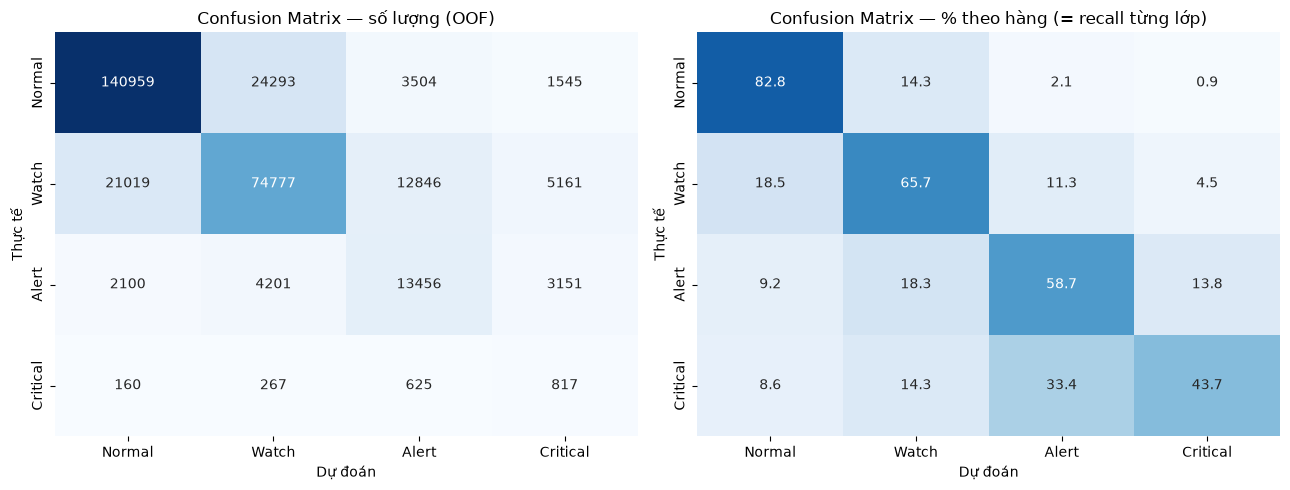

In [22]:
completed_folds = [k for k in range(N_FOLDS) if os.path.exists(f"{MODEL_DIR}/fold_{k}.txt")]
print(f"Dùng {len(completed_folds)}/{N_FOLDS} fold đã train xong để vẽ confusion matrix")

oof_pred_cm = np.full(len(dev_enc), -1)
mask_available = np.zeros(len(dev_enc), dtype=bool)

for k in completed_folds:
    va_mask = (fold_id == k).values
    booster = lgb.Booster(model_file=f"{MODEL_DIR}/fold_{k}.txt")
    proba = booster.predict(X_dev[va_mask])
    oof_pred_cm[va_mask] = np.argmax(proba, axis=1)
    mask_available |= va_mask

cm = confusion_matrix(y_dev[mask_available], oof_pred_cm[mask_available], labels=[0, 1, 2, 3])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[0], cbar=False)
axes[0].set_title("Confusion Matrix — số lượng (OOF)")
axes[0].set_xlabel("Dự đoán"); axes[0].set_ylabel("Thực tế")

sns.heatmap(cm_norm, annot=True, fmt=".1f", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=axes[1], cbar=False, vmin=0, vmax=100)
axes[1].set_title("Confusion Matrix — % theo hàng (= recall từng lớp)")
axes[1].set_xlabel("Dự đoán"); axes[1].set_ylabel("Thực tế")

plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/confusion_matrix.png", dpi=120)
plt.show()

## 6.7 Feature importance — bar chart
Trung bình importance qua 5 model (mỗi fold 1 model), vẽ bar chart ngang cho 15 feature quan trọng nhất — trực quan hơn bảng số khi cần nhìn nhanh feature nào đang chi phối quyết định của model.

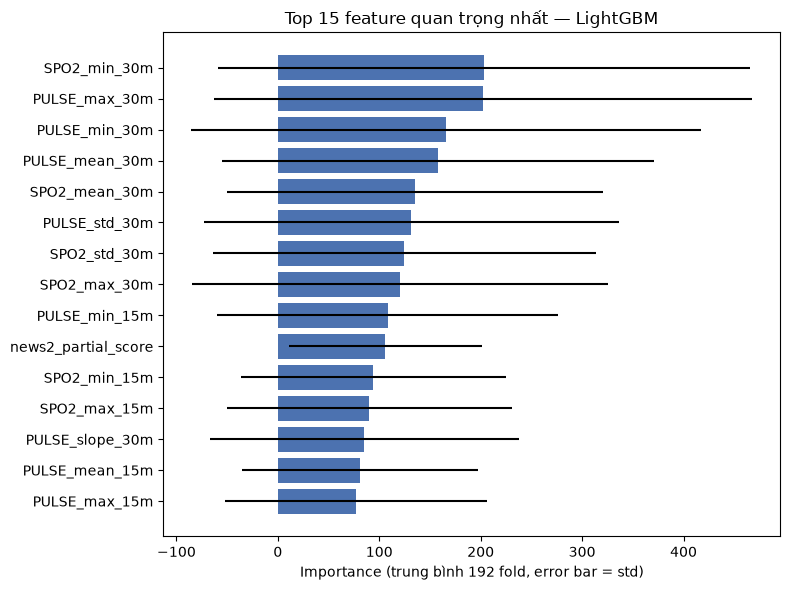

In [ ]:
completed_folds = [k for k in range(N_FOLDS) if os.path.exists(f"{MODEL_DIR}/fold_{k}.txt")]

importances = []
for k in completed_folds:
    booster = lgb.Booster(model_file=f"{MODEL_DIR}/fold_{k}.txt")
    importances.append(booster.feature_importance())

importance_df = pd.DataFrame(np.array(importances).T, index=FEATURE_COLS,
                              columns=[f"fold_{k}" for k in range(N_FOLDS)])
importance_df["mean"] = importance_df.mean(axis=1)
importance_df["std"] = importance_df.iloc[:, :N_FOLDS].std(axis=1)

top15 = importance_df.sort_values("mean", ascending=False).head(15)

plt.figure(figsize=(8, 6))
plt.barh(top15.index[::-1], top15["mean"][::-1], xerr=top15["std"][::-1], color="#4c72b0")
plt.xlabel(f"Importance (trung bình {N_FOLDS} fold, error bar = std)")
plt.title("Top 15 feature quan trọng nhất — LightGBM")
plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/feature_importance.png", dpi=120)
plt.show()

### Xem đầy đủ thứ hạng 41 feature — kiểm tra risk_level/spo2_score/pulse_score đang xếp hạng bao nhiêu

In [24]:
pd.set_option("display.max_rows", 50)
importance_df.sort_values("mean", ascending=False)[["mean", "std"]]

,mean,std
SPO2_min_30m,203.322917,262.481014
PULSE_max_30m,202.192708,265.285422
PULSE_min_30m,166.223958,251.409757
PULSE_mean_30m,157.927083,212.922459
SPO2_mean_30m,135.276042,185.397357
PULSE_std_30m,131.718750,204.871800
SPO2_std_30m,124.854167,189.152172
SPO2_max_30m,120.343750,204.857725
PULSE_min_15m,108.416667,168.186083
news2_partial_score,106.104167,95.431506


## 6.8 Model có "biết" Critical nhưng bị argmax che mất không?

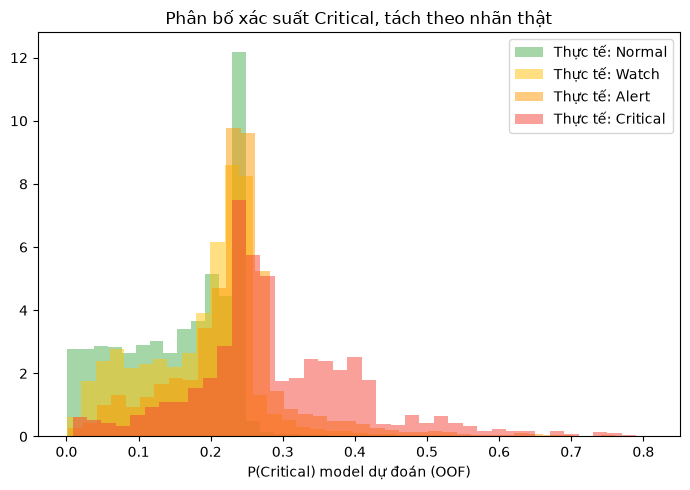

P(Critical) trung bình khi nhãn thật là Critical: 0.29
P(Critical) trung bình khi nhãn thật KHÔNG phải Critical: 0.173


In [ ]:
oof_proba_critical = np.full(len(dev_enc), np.nan)

for k in range(N_FOLDS):
    va_mask = (fold_id == k).values
    if va_mask.sum() == 0:
        continue
    booster = lgb.Booster(model_file=f"{MODEL_DIR}/fold_{k}.txt")
    proba = booster.predict(X_dev[va_mask])          # shape (n, 4), cột 3 = P(Critical)
    oof_proba_critical[va_mask] = proba[:, 3]

fig, ax = plt.subplots(figsize=(7, 5))
for cls, color in zip(CLASS_NAMES, ["#4CAF50", "#FFC107", "#FF9800", "#F44336"]):
    mask = (y_dev.values == RISK_ORDER[cls])
    ax.hist(oof_proba_critical[mask], bins=40, alpha=0.5, label=f"Thực tế: {cls}", color=color, density=True)
ax.set_xlabel("P(Critical) model dự đoán (OOF)")
ax.set_title("Phân bố xác suất Critical, tách theo nhãn thật")
ax.legend()
plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/proba_critical_by_true_label.png", dpi=120)
plt.show()

print("P(Critical) trung bình khi nhãn thật là Critical:", oof_proba_critical[y_dev.values == 3].mean().round(3))
print("P(Critical) trung bình khi nhãn thật KHÔNG phải Critical:", oof_proba_critical[y_dev.values != 3].mean().round(3))

# Xem model có "nghe" tín hiệu PULSE khi ra quyết định Critical không
high_pulse_mask = dev_enc["PULSE_max_30m"] > dev_enc["PULSE_max_30m"].quantile(0.75)
print("P(Critical) trung bình khi PULSE_max_30m cao (top 25%):", oof_proba_critical[high_pulse_mask.values].mean().round(3))
print("P(Critical) trung bình khi PULSE_max_30m thấp (75% còn lại):", oof_proba_critical[~high_pulse_mask.values].mean().round(3))

## 6.9 Tối ưu ngưỡng quyết định cho Critical (thay vì argmax)

ROC-AUC (Critical vs rest): 0.816   |   Average Precision: 0.056


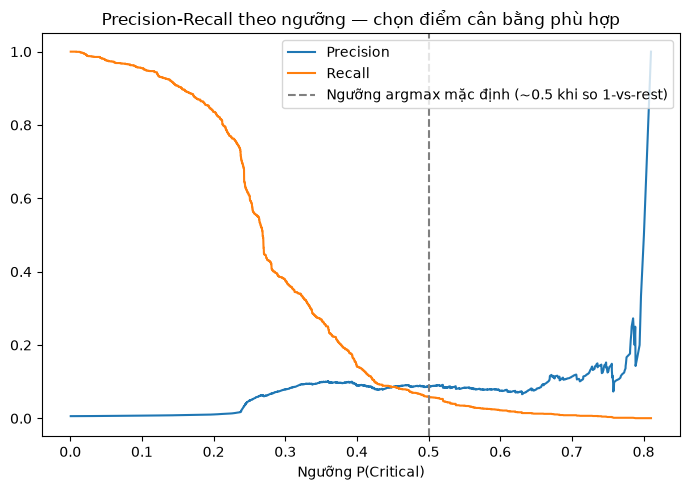

Ngưỡng 0.15: recall=0.907, precision=0.009, bắt 1695 ca thật, báo giả 196576 lần
Ngưỡng 0.2: recall=0.836, precision=0.011, bắt 1562 ca thật, báo giả 144614 lần
Ngưỡng 0.25: recall=0.608, precision=0.049, bắt 1136 ca thật, báo giả 22231 lần
Ngưỡng 0.3: recall=0.376, precision=0.079, bắt 703 ca thật, báo giả 8208 lần
Ngưỡng 0.35: recall=0.270, precision=0.099, bắt 505 ca thật, báo giả 4592 lần


In [29]:
from sklearn.metrics import precision_recall_curve, roc_auc_score, average_precision_score

y_true_binary = (y_dev.values == 3).astype(int)
valid_mask = ~np.isnan(oof_proba_critical)

auc = roc_auc_score(y_true_binary[valid_mask], oof_proba_critical[valid_mask])
ap = average_precision_score(y_true_binary[valid_mask], oof_proba_critical[valid_mask])
print(f"ROC-AUC (Critical vs rest): {auc:.3f}   |   Average Precision: {ap:.3f}")

precisions, recalls, thresholds = precision_recall_curve(y_true_binary[valid_mask], oof_proba_critical[valid_mask])

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(thresholds, precisions[:-1], label="Precision")
ax.plot(thresholds, recalls[:-1], label="Recall")
ax.axvline(0.5, color="gray", linestyle="--", label="Ngưỡng argmax mặc định (~0.5 khi so 1-vs-rest)")
ax.set_xlabel("Ngưỡng P(Critical)")
ax.legend()
ax.set_title("Precision-Recall theo ngưỡng — chọn điểm cân bằng phù hợp")
plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/critical_threshold_curve.png", dpi=120)
plt.show()

# Thử vài ngưỡng cụ thể, xem đánh đổi thực tế
for t in [0.15, 0.20, 0.25, 0.30, 0.35]:
    pred_binary = (oof_proba_critical[valid_mask] >= t).astype(int)
    tp = ((pred_binary == 1) & (y_true_binary[valid_mask] == 1)).sum()
    fp = ((pred_binary == 1) & (y_true_binary[valid_mask] == 0)).sum()
    fn = ((pred_binary == 0) & (y_true_binary[valid_mask] == 1)).sum()
    recall_t = tp / (tp + fn) if (tp+fn) > 0 else 0
    precision_t = tp / (tp + fp) if (tp+fp) > 0 else 0
    print(f"Ngưỡng {t}: recall={recall_t:.3f}, precision={precision_t:.3f}, "
          f"bắt {tp} ca thật, báo giả {fp} lần")